<img src='https://github.com/Ikomia-dev/notebooks/blob/main/examples/img/banner_ikomia.png?raw=true'>




# How to run Qwen2.5-VL with the Ikomia API

Qwen2.5-VL is the latest flagship vision-language model (VLM) from Qwen, designed to understand images, videos, documents, interfaces, and text in a single unified system. 

It’s built around three big ideas:
- A redesigned, fast Vision Transformer that preserves detail
- Native dynamic-resolution input for both images and video frames
- A clever absolute-time position encoding that helps track events in long videos

Thanks to these choices, Qwen2.5-VL excels at reading complex PDFs, grounding objects inside images, tracking events in long videos, and even interacting with user interfaces. Models come in multiple sizes (3B, 7B, 32B, 72B), the weights are openly available, and you can run them with only a few lines of code via the Ikomia API.
OWLv2 is an open-vocabulary object detection developed by researchers at Google DeepMind. OWLv2 builds on the foundation of OWL-ViT but introduces key innovations to dramatically scale up training and improve performance.

## Setup

Please use a GPU for this tutorial.

In the Google colab menu, select "Runtime" then "Change runtime type", choose GPU in "Hardware accelerator".

Check your GPU with the following command:

In [1]:
!nvidia-smi

Thu Jun 27 11:47:40 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla T4                       Off | 00000000:00:04.0 Off |                    0 |
| N/A   56C    P8              10W /  70W |      0MiB / 15360MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

First, you need to install Ikomia API pip package.

In [ ]:
pip install ikomia

## Run Qwen2.5-VL on your image

In [6]:
from ikomia.dataprocess.workflow import Workflow
from ikomia.utils.displayIO import display

# Init your workflow
wf = Workflow()

# Add algorithm
algo = wf.add_task(name="infer_qwen2_5_vl", auto_connect=True)

algo.set_parameters({
    "model_name": "Qwen/Qwen2.5-VL-3B-Instruct",
    "cuda": "True",
    "prompt": "Read all the text in the image.",
    "max_new_tokens": "512", 
    "do_sample": "False",
    "temperature": "1",
    "top_p": "1",
    "top_k": "50",
    "repetition_penalty": "1.0"
})

# Run on your image  
wf.run_on(url='https://github.com/NanoNets/docext/blob/main/assets/invoice_test.jpeg?raw=true')

# Display input image
# display(algo.get_input(0).get_image())



invoice_test.jpeg: 100%|██████████| 52.7k/52.7k [00:00<00:00, 628kiB/s]
Loading checkpoint shards: 100%|██████████| 2/2 [00:17<00:00,  8.52s/it]


INVOICE
#1024

BILLED TO: Really Great Company
PAY TO: Avery Davis
123 Anywhere St., Any City
123-456-7890
Bank Really Great Bank
Account Name John Smith
BSB 000-000
Account Number 0000 0000

| DESCRIPTION | RATE | HOURS | AMOUNT |
|-------------|------|-------|--------|
| Content Plan | $50/hr | 4 | $200.00 |
| Copy Writing | $50/hr | 2 | $100.00 |
| Website Design | $50/hr | 5 | $250.00 |
| Website Development | $100/hr | 5 | $500.00 |
| SEO | $50/hr | 4 | $200.00 |

Sub-Total | $1,250.00 |
Package Discount (30%) | $375.00 |

TOTAL | $875.00 |

Payment is required within 14 business days of invoice date. Please send remittance to hello@reallygreatsite.com.

Thank you for your business.
Workflow Untitled run successfully in 511025.3417 ms.


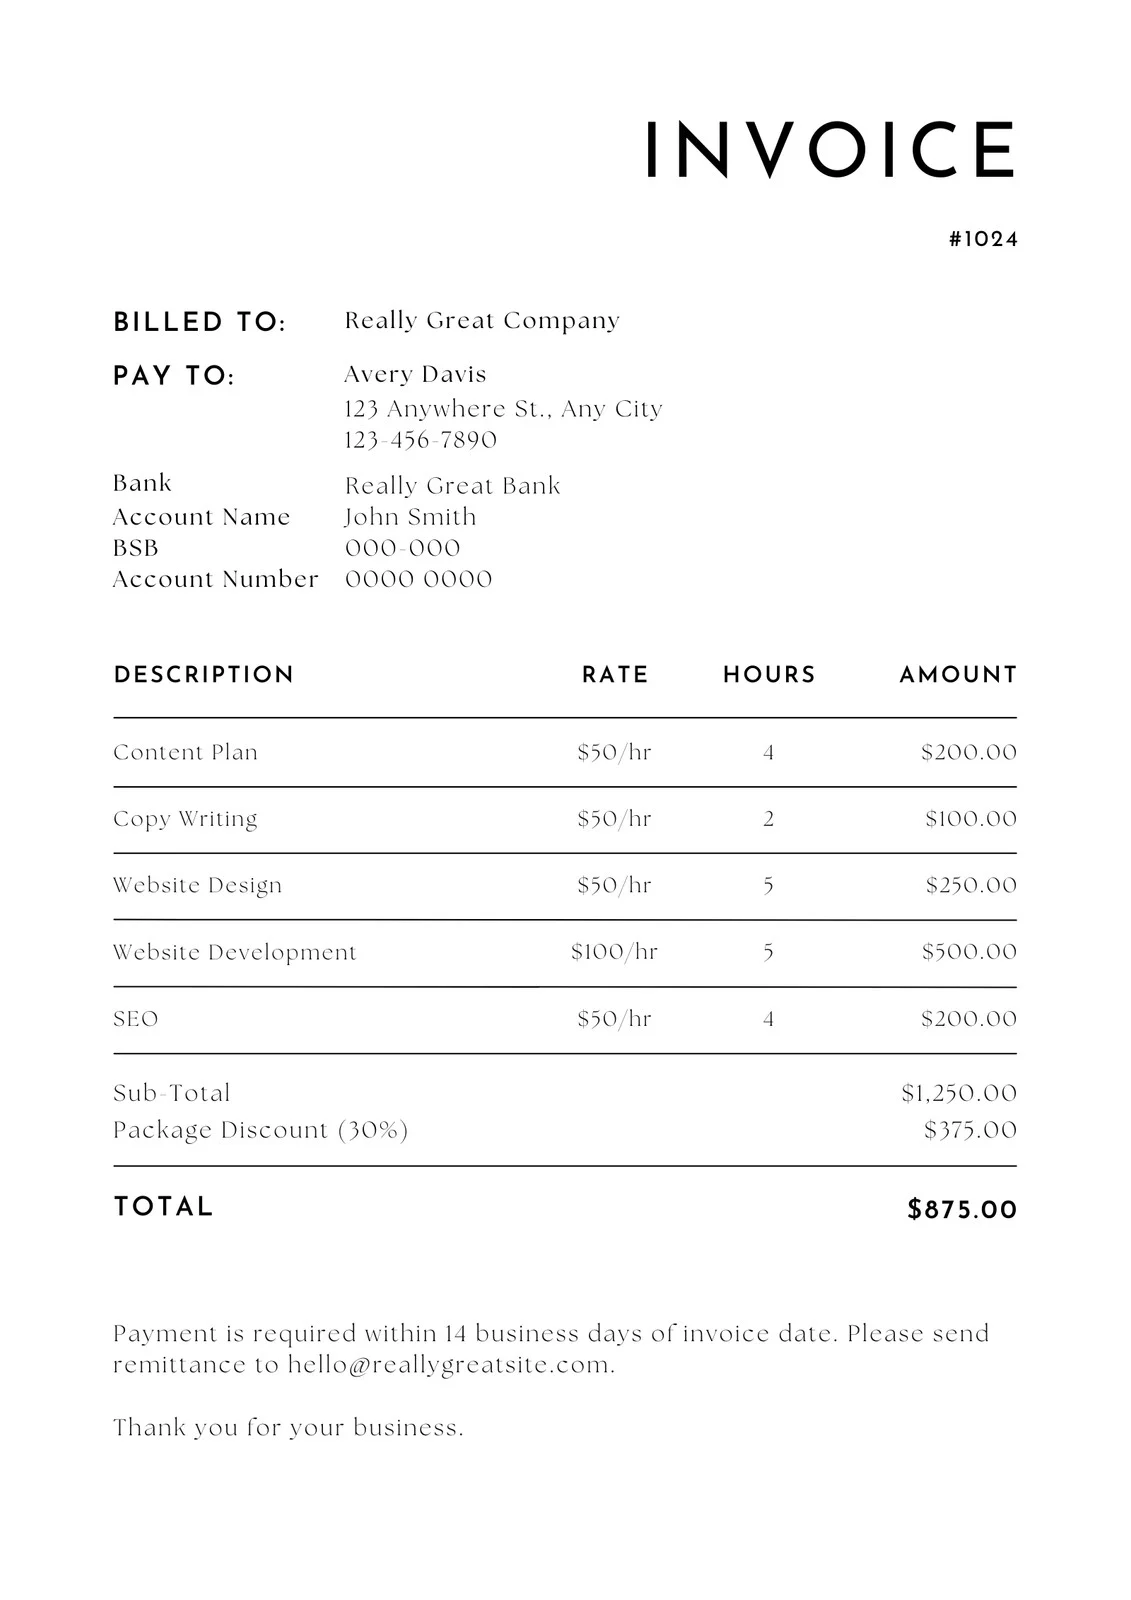

In [2]:
# Display image on Google Colab
from PIL import ImageShow
ImageShow.register(ImageShow.IPythonViewer(), 0)
display(algo.get_input(0).get_image())

In [5]:
# Save output .json
qwen_output = algo.get_output(1)
qwen_output.save('qwen_output.json')

List of parameters:

- **model_name** — Name or path of the [Qwen2.5-VL model](https://huggingface.co/collections/Qwen/qwen25-vl). Default: "Qwen/Qwen2.5-VL-3B-Instruct".
- **prompt** — Custom prompt to guide the model’s response for the given image. Default: "Describe the image in detail."
- **system_prompt** — System prompt to set the behavior and context for the model. Default: "You are a helpful assistant."
- **cuda** — If True, use CUDA (GPU). If False, run on CPU.
- **do_sample** — Use sampling (True) or greedy decoding (False). When True, token validation incorporates resampling for more diverse outputs. Default: False.
- **max_new_tokens** — Maximum number of tokens to generate (excluding prompt tokens). Default: 512. For “essais” reports, reducing this value can speed up inference and mitigate hallucinations.
- **temperature** — Sampling temperature. Default: 1. (Only used if --do_sample=True.)
- **top_p** — Top-p sampling parameter. Default: 1. (Only used if --do_sample=True.)
- **top_k** — Top-k sampling parameter. Default: 50. (Only used if --do_sample=True.)
- **repetition_penalty** — Repetition penalty (1.0 means no penalty). Default: 1.0.
